# 03 · Tiempo de permanencia en urgencias (LOS) 

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import config
from src.estadistica import ecdf_en_malla, tabla_los
from src.graficos import (
    COLORES_GRUPO,
    DIAS_SEMANA,
    ETIQUETAS_CORTAS_GRUPO,
    ETIQUETAS_GRUPO,
    TEXTO_PRIMARIO,
    TEXTO_SECUNDARIO,
    ancho_linea,
    aplicar_estilo,
    guardar_figura,
    heatmap_hora_dia,
    marcar_umbrales,
    rotular_barras,
)
from src.privacidad import enmascarar_pequenos, tabla_segura

aplicar_estilo()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

G1, G2, G3, G4 = config.GRUPOS
UMBRAL = config.UMBRAL_OPERATIVO_H
SUFIJO = f'mas_{UMBRAL}h'

In [2]:
ruta_episodios = config.DATA_INTERIM / f'episodios_urgencias_{config.UMBRAL_FUSION_MIN}min.parquet'
if not ruta_episodios.exists():
    raise FileNotFoundError('No existe el parquet de episodios: ejecuta primero notebooks/02_episodios.ipynb.')

episodios = pd.read_parquet(ruta_episodios)
episodios['hora_llegada'] = episodios['llegada'].dt.hour
episodios['dia_semana'] = episodios['llegada'].dt.dayofweek
episodios['mes'] = episodios['llegada'].dt.to_period('M').dt.to_timestamp()
tiempos = episodios[episodios['grupo'].isin(list(config.GRUPOS_TIEMPOS))]
print('Episodios (filas, columnas):', episodios.shape)
print('Episodios con tiempos (grupos 2 y 3):', len(tiempos))

Episodios (filas, columnas): (440202, 33)
Episodios con tiempos (grupos 2 y 3): 230774


## 1. Tamaño de los grupos de análisis

Figura de contexto del informe: los tiempos solo se analizan en los grupos 2 y 3 (D6).

In [3]:
tamano = (
    episodios['grupo'].value_counts()
    .reindex(list(config.GRUPOS), fill_value=0)
    .rename_axis('grupo')
    .rename('n_episodios')
    .to_frame()
)
tamano['pct_episodios'] = 100 * tamano['n_episodios'] / tamano['n_episodios'].sum()
tabla_segura(tamano, decimales=1)

,n_episodios,pct_episodios
grupo,,
1_contacto_breve,203136,46.1
2_no_hosp_atencion,194392,44.2
3_hosp_con_hora_piso,36382,8.3
4_hosp_sin_hora_piso,6292,1.4


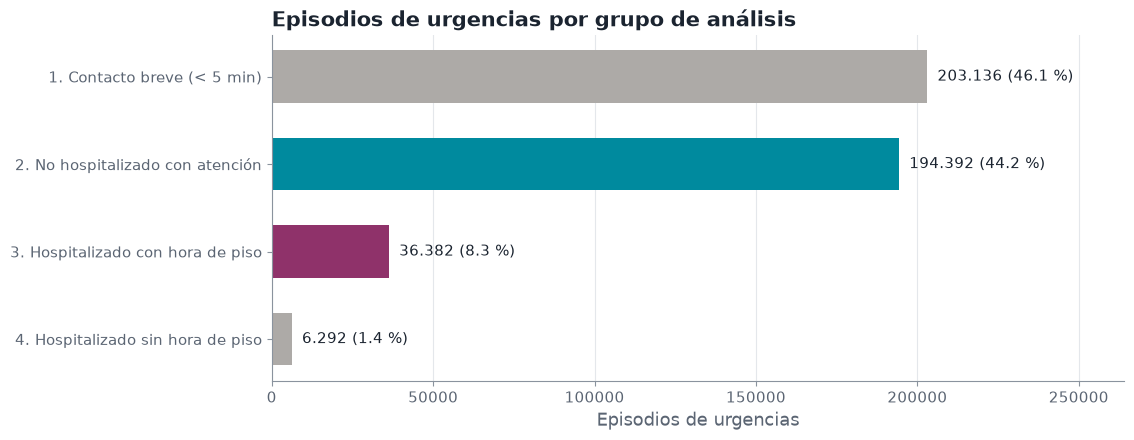

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(tamano))[::-1]
ax.barh(y, tamano['n_episodios'], height=0.6, color=[COLORES_GRUPO[g] for g in tamano.index])
for yi, n, pct in zip(y, tamano['n_episodios'], tamano['pct_episodios']):
    texto = f'<{config.MIN_CELDA}' if n < config.MIN_CELDA else f'{n:,.0f}'.replace(',', '.') + f' ({pct:.1f} %)'
    ax.text(n, yi, '  ' + texto, va='center', color=TEXTO_PRIMARIO, fontsize=11)
ax.set_yticks(y, [ETIQUETAS_GRUPO[g] for g in tamano.index])
ax.set_xlim(0, tamano['n_episodios'].max() * 1.3)
ax.grid(False)
ax.grid(axis='x')
ax.set_xlabel('Episodios de urgencias')
ax.set_title('Episodios de urgencias por grupo de análisis')
guardar_figura(fig, '03_tamano_grupos')
plt.show()

## 2. Distribución del LOS 

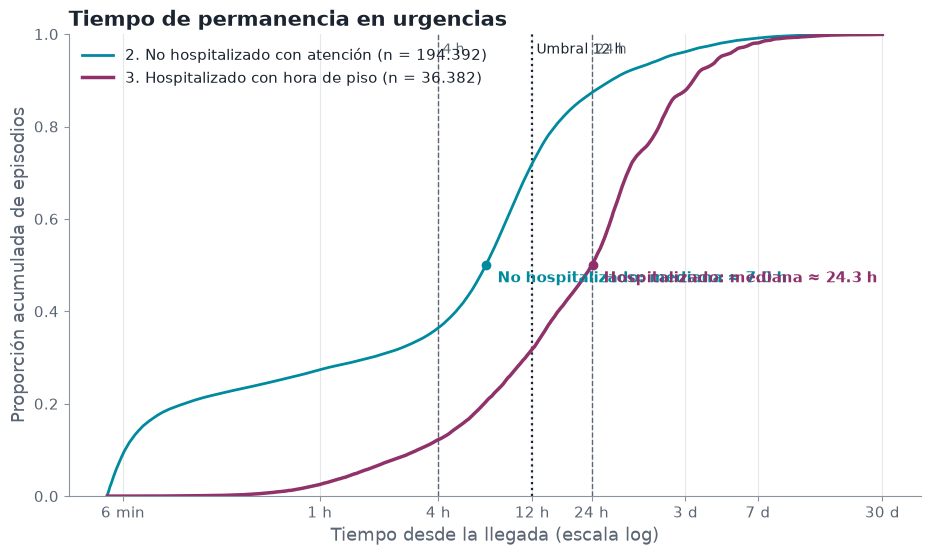

In [15]:
malla = np.logspace(np.log10(5 / 60), np.log10(24 * 30), 600)

fig, ax = plt.subplots(figsize=(11, 6))
for grupo in config.GRUPOS_TIEMPOS:
    los = tiempos.loc[tiempos['grupo'] == grupo, 'los_h']
    n_validos = int(los.notna().sum())
    etiqueta = f'{ETIQUETAS_GRUPO[grupo]} (n = ' + f'{n_validos:,.0f}'.replace(',', '.') + ')'
    ecdf = ecdf_en_malla(los, malla)
    color = COLORES_GRUPO[grupo]
    ax.plot(malla, ecdf, color=color, linewidth=ancho_linea(grupo), label=etiqueta)
    # Etiqueta directa en el punto donde la curva cruza la mediana.
    cruce = np.flatnonzero(ecdf >= 0.5)
    if cruce.size:
        x_mediana = malla[cruce[0]]
        ax.plot(x_mediana, 0.5, 'o', color=color, markersize=6)
        ax.annotate(f'{ETIQUETAS_CORTAS_GRUPO[grupo]}: mediana ≈ {x_mediana:.1f} h', xy=(x_mediana, 0.5),
                    xytext=(8, -4), textcoords='offset points', va='top', color=color, fontsize=11,
                    fontweight='bold')
ax.set_xscale('log')
marcar_umbrales(ax, [4, 12, 24])
ax.set_xticks([0.1, 1, 4, 12, 24, 72, 168, 720], ['6 min', '1 h', '4 h', '12 h', '24 h', '3 d', '7 d', '30 d'])
ax.minorticks_off()
ax.set_ylim(0, 1)
ax.grid(axis='both')
ax.set_xlabel('Tiempo desde la llegada (escala log)')
ax.set_ylabel('Proporción acumulada de episodios')
ax.set_title('Tiempo de permanencia en urgencias')
ax.legend(loc='upper left')
guardar_figura(fig, '03_ecdf_los')
plt.show()

## 3. Resumen del LOS por grupo

n, mediana, p25, p75 y p90 en horas, y porcentaje por encima de cada umbral (4, 6, 8, 12, 24 y 72 h) con intervalo de confianza de Wilson al 95 %.

In [6]:
resumen_grupos = tabla_los(tiempos, ['grupo'])
tabla_segura(resumen_grupos)

,n,mediana_h,p25_h,p75_h,p90_h,n_mas_4h,pct_mas_4h,ic_inf_mas_4h,ic_sup_mas_4h,n_mas_6h,pct_mas_6h,ic_inf_mas_6h,ic_sup_mas_6h,n_mas_8h,pct_mas_8h,ic_inf_mas_8h,ic_sup_mas_8h,n_mas_12h,pct_mas_12h,ic_inf_mas_12h,ic_sup_mas_12h,n_mas_24h,pct_mas_24h,ic_inf_mas_24h,ic_sup_mas_24h,n_mas_72h,pct_mas_72h,ic_inf_mas_72h,ic_sup_mas_72h
grupo,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2_no_hosp_atencion,194392,6.97,0.61,13.06,30.19,123565,63.56,63.35,63.78,106929,55.01,54.79,55.23,86761,44.63,44.41,44.85,54330,27.95,27.75,28.15,24697,12.70,12.56,12.85,7404,3.81,3.72,3.89
3_hosp_con_hora_piso,36382,24.02,8.79,43.73,78.85,31934,87.77,87.43,88.11,29975,82.39,81.99,82.78,28008,76.98,76.55,77.41,24799,68.16,67.68,68.64,18206,50.04,49.53,50.55,4417,12.14,11.81,12.48


## 4. LOS por grupo etario y sexo

In [16]:
columnas = ['n', 'mediana_h', 'p25_h', 'p75_h', 'p90_h', f'n_{SUFIJO}', f'pct_{SUFIJO}', f'ic_inf_{SUFIJO}', f'ic_sup_{SUFIJO}']
for variable in ['grupo_etario', 'sexo']:
    display(tabla_segura(tabla_los(tiempos, ['grupo', variable])[columnas]))

n  mediana_h      p25_h      p75_h      p90_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h
grupo                grupo_etario                                                                                                        
2_no_hosp_atencion   adulto        119358       7.53       1.88      13.38      30.19     34696       29.07          28.81          29.33
                     adulto_mayor   25710       9.36       4.36      17.97      55.48      9776       38.02          37.43          38.62
                     pediatria      49317       2.42       0.12       9.86      21.72      9856       19.98          19.63          20.34
                     sin_dato         <10  suprimido  suprimido  suprimido  suprimido       <10   suprimido      suprimido      suprimido
3_hosp_con_hora_piso adulto         21236       26.3      10.82      46.57       79.2     15409       72.56          71.96          73.16
                     adulto_mayor    7258      28.41       8.76      53.94      93.54      5075       69.92          68.86          70.97
                     pediatria       7888      14.07       6.26      30.92      57.35      4315        54.7           53.6           55.8

n  mediana_h  p25_h  p75_h  p90_h n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h
grupo                sexo                                                                                                       
2_no_hosp_atencion   femenino         112680       7.19   0.99  12.98  28.61     31401       27.87          27.61          28.13
                     masculino         81692       6.63   0.34  13.18  32.49     22920       28.06          27.75          28.37
                     otro_o_sin_dato      20      10.19   1.61  21.97  35.42       <10   suprimido      suprimido      suprimido
3_hosp_con_hora_piso femenino          20724      24.36   9.48  43.10  77.90     14386       69.42          68.79          70.04
                     masculino         15658      23.62   7.84  44.57  80.14     10413        66.5          65.76          67.24

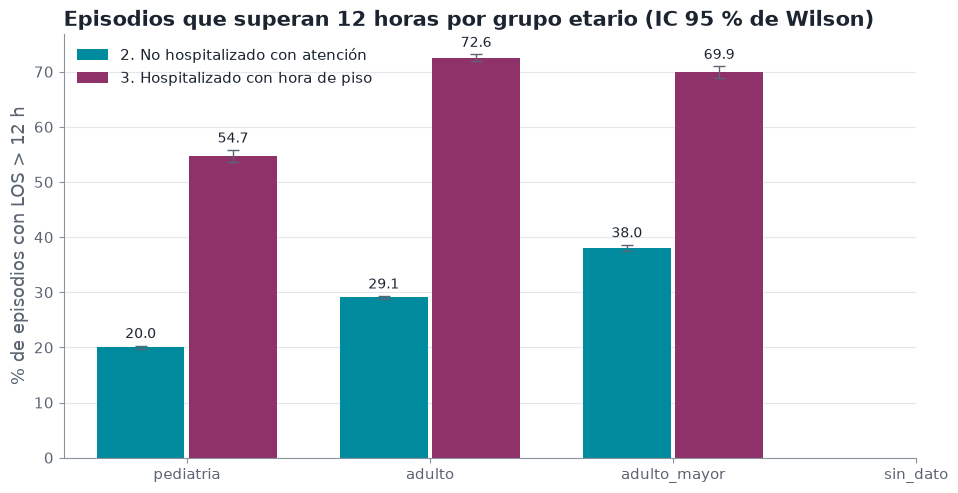

In [17]:
por_edad = tabla_los(tiempos, ['grupo_etario', 'grupo'], umbrales=[UMBRAL])
valido = (por_edad['n'] >= config.MIN_CELDA) & (por_edad[f'n_{SUFIJO}'] >= config.MIN_CELDA)
pct = por_edad[f'pct_{SUFIJO}'].where(valido).unstack('grupo')
inferior = por_edad[f'ic_inf_{SUFIJO}'].where(valido).unstack('grupo')
superior = por_edad[f'ic_sup_{SUFIJO}'].where(valido).unstack('grupo')
categorias = [c for c in ['pediatria', 'adulto', 'adulto_mayor', 'sin_dato'] if c in pct.index]

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(categorias))
for j, grupo in enumerate(config.GRUPOS_TIEMPOS):
    if grupo not in pct.columns:
        continue
    valores = pct.loc[categorias, grupo]
    errores = np.vstack([
        (valores - inferior.loc[categorias, grupo]).to_numpy(),
        (superior.loc[categorias, grupo] - valores).to_numpy(),
    ])
    barras = ax.bar(x + (j - 0.5) * 0.38, valores, width=0.36, color=COLORES_GRUPO[grupo],
                    label=ETIQUETAS_GRUPO[grupo], yerr=errores, capsize=4,
                    error_kw={'elinewidth': 1, 'ecolor': TEXTO_SECUNDARIO})
    rotular_barras(ax, barras, valores, alturas=superior.loc[categorias, grupo])
ax.set_xticks(x, categorias)
ax.set_ylabel(f'% de episodios con LOS > {UMBRAL} h')
ax.set_title(f'Episodios que superan {UMBRAL} horas por grupo etario (IC 95 % de Wilson)')
ax.legend()
guardar_figura(fig, '03_mas_12h_grupo_etario')
plt.show()

## 5. Hora de llegada y día de la semana

Mapas de calor hora × día: % de episodios del grupo 3 con LOS > 12 h y mediana del LOS del grupo 2. Las celdas con menos de 10 episodios quedan en blanco.

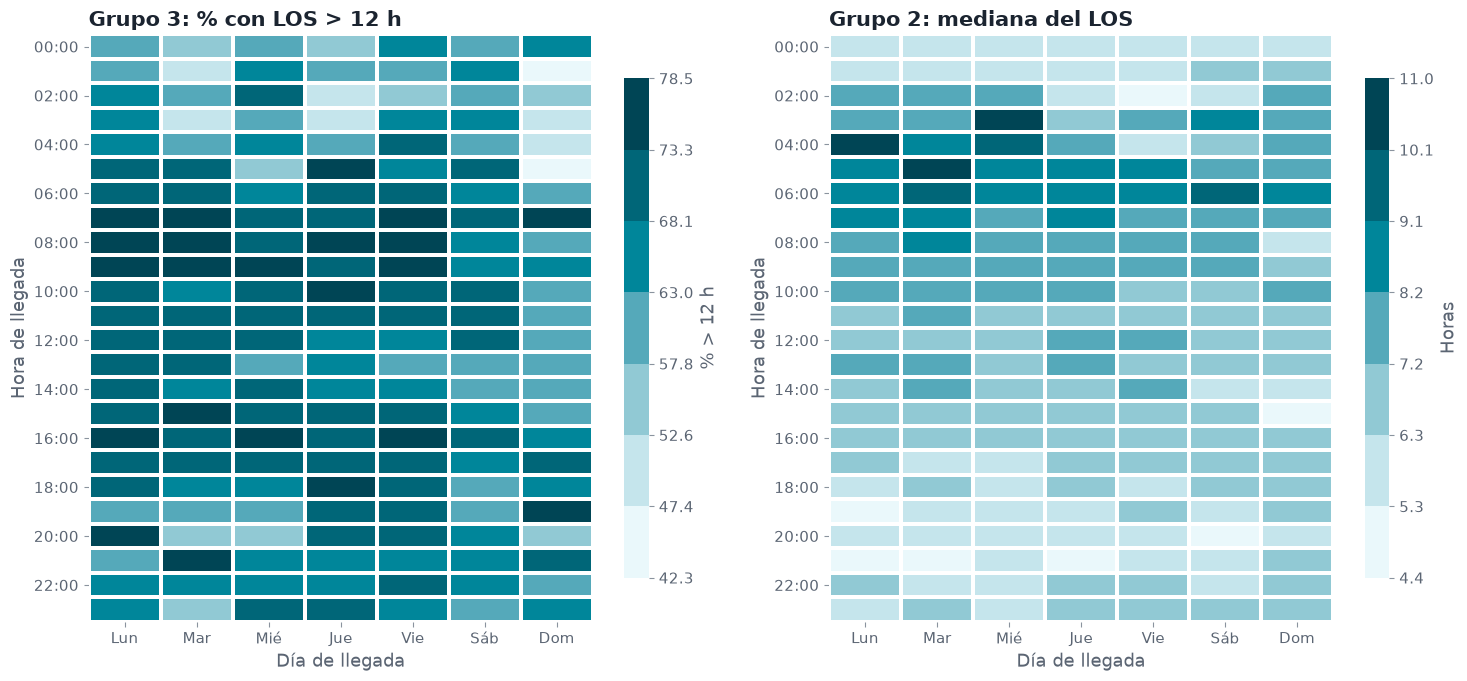

In [18]:
def matriz_hora_dia(datos, columna, estadistico):
    agrupado = datos.groupby(['hora_llegada', 'dia_semana'])[columna]
    n = agrupado.size().unstack('dia_semana')
    valores = agrupado.agg(estadistico).unstack('dia_semana')
    return enmascarar_pequenos(valores, n)


g3 = tiempos[(tiempos['grupo'] == G3) & tiempos['los_h'].notna()].assign(
    supera_umbral=lambda d: 100.0 * (d['los_h'] > UMBRAL)
)
g2 = tiempos[(tiempos['grupo'] == G2) & tiempos['los_h'].notna()]
pct_g3 = matriz_hora_dia(g3, 'supera_umbral', 'mean')
mediana_g2 = matriz_hora_dia(g2, 'los_h', 'median')

fig, ejes = plt.subplots(1, 2, figsize=(15, 7))
heatmap_hora_dia(ejes[0], pct_g3, f'Grupo 3: % con LOS > {UMBRAL} h', f'% > {UMBRAL} h')
heatmap_hora_dia(ejes[1], mediana_g2, 'Grupo 2: mediana del LOS', 'Horas')
fig.tight_layout()
guardar_figura(fig, '03_heatmap_hora_dia')
plt.show()

## 6. Tendencia mensual

Hasta `FECHA_CORTE_TENDENCIAS` (2026-06-30, D9): mediana del LOS y % > 12 h del grupo 3 (con IC de Wilson), y número de episodios del grupo 2.

In [19]:
hasta_corte = tiempos[tiempos['llegada'] <= config.FECHA_CORTE_TENDENCIAS]
mensual_g3 = tabla_los(hasta_corte[hasta_corte['grupo'] == G3], ['mes'], umbrales=[UMBRAL])
mensual_g2 = hasta_corte[hasta_corte['grupo'] == G2].groupby('mes').size().rename('n_episodios_g2').to_frame()
display(tabla_segura(mensual_g3))
display(tabla_segura(mensual_g2))

,n,mediana_h,p25_h,p75_h,p90_h,n_mas_12h,pct_mas_12h,ic_inf_mas_12h,ic_sup_mas_12h
mes,,,,,,,,,
2023-01-01,1008,22.84,10.08,36.03,60.60,708,70.24,67.34,72.98
2023-02-01,857,23.89,10.44,39.13,74.91,626,73.05,69.98,75.91
2023-03-01,995,23.47,9.04,40.56,71.99,688,69.15,66.21,71.94
2023-04-01,1003,24.02,10.42,34.73,59.07,708,70.59,67.69,73.33
2023-05-01,997,25.50,10.44,38.59,79.13,715,71.72,68.84,74.42
2023-06-01,967,25.08,8.88,43.00,79.43,674,69.70,66.73,72.51
2023-07-01,983,25.22,10.01,39.07,62.33,697,70.91,67.99,73.66
2023-08-01,998,25.96,9.59,41.14,73.25,701,70.24,67.33,73.00
2023-09-01,897,23.87,9.05,39.42,71.11,619,69.01,65.91,71.95


,n_episodios_g2
mes,
2023-01-01,4666
2023-02-01,4203
2023-03-01,5195
2023-04-01,4607
2023-05-01,4997
2023-06-01,4866
2023-07-01,4962
2023-08-01,5012
2023-09-01,4812


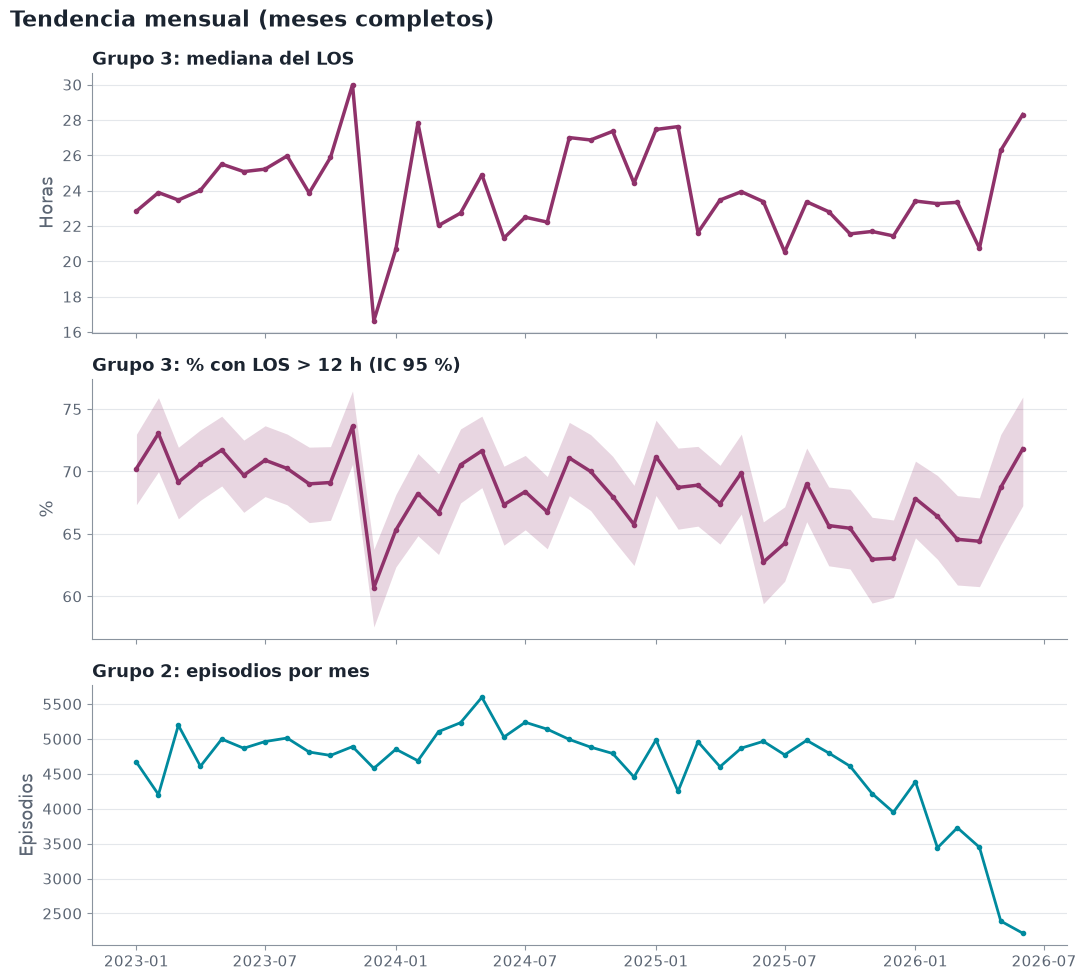

In [20]:
valido = (mensual_g3['n'] >= config.MIN_CELDA) & (mensual_g3[f'n_{SUFIJO}'] >= config.MIN_CELDA)
fig, ejes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

ejes[0].plot(mensual_g3.index, mensual_g3['mediana_h'].where(mensual_g3['n'] >= config.MIN_CELDA),
             marker='o', markersize=3, color=COLORES_GRUPO[G3], linewidth=ancho_linea(G3))
ejes[0].set_ylabel('Horas')
ejes[0].set_title('Grupo 3: mediana del LOS', fontsize=13)

ejes[1].plot(mensual_g3.index, mensual_g3[f'pct_{SUFIJO}'].where(valido),
             marker='o', markersize=3, color=COLORES_GRUPO[G3], linewidth=ancho_linea(G3))
ejes[1].fill_between(mensual_g3.index, mensual_g3[f'ic_inf_{SUFIJO}'].where(valido),
                     mensual_g3[f'ic_sup_{SUFIJO}'].where(valido), color=COLORES_GRUPO[G3], alpha=0.2, linewidth=0)
ejes[1].set_ylabel('%')
ejes[1].set_title(f'Grupo 3: % con LOS > {UMBRAL} h (IC 95 %)', fontsize=13)

n_g2 = enmascarar_pequenos(mensual_g2['n_episodios_g2'], mensual_g2['n_episodios_g2'])
ejes[2].plot(n_g2.index, n_g2, marker='o', markersize=3, color=COLORES_GRUPO[G2], linewidth=ancho_linea(G2))
ejes[2].set_ylabel('Episodios')
ejes[2].set_title('Grupo 2: episodios por mes', fontsize=13)

fig.suptitle('Tendencia mensual (meses completos)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar_figura(fig, '03_tendencia_mensual')
plt.show()

## 7. Contactos breves (grupo 1)

Volumen por hora del día y por mes, para ayudar a entender qué son estos contactos de menos de 5 minutos. No se analizan tiempos.

In [21]:
breves = episodios[episodios['grupo'] == G1]
por_hora = pd.DataFrame({
    'n_contactos_breves': breves.groupby('hora_llegada').size(),
    'n_episodios': episodios.groupby('hora_llegada').size(),
}).fillna(0).astype('int64').rename_axis('hora_llegada')
por_hora['pct_contactos_breves'] = 100 * por_hora['n_contactos_breves'] / por_hora['n_episodios']
display(tabla_segura(por_hora))

episodios_corte = episodios[episodios['llegada'] <= config.FECHA_CORTE_TENDENCIAS]
breves_corte = episodios_corte[episodios_corte['grupo'] == G1]
por_mes = pd.DataFrame({
    'n_contactos_breves': breves_corte.groupby('mes').size(),
    'n_episodios': episodios_corte.groupby('mes').size(),
}).fillna(0).astype('int64').rename_axis('mes')
por_mes['pct_contactos_breves'] = 100 * por_mes['n_contactos_breves'] / por_mes['n_episodios']
display(tabla_segura(por_mes))

,n_contactos_breves,n_episodios,pct_contactos_breves
hora_llegada,,,
0,3210,7149,44.90
1,2480,5328,46.55
2,1966,4429,44.39
3,1850,4071,45.44
4,1718,3946,43.54
5,3093,6541,47.29
6,6639,13359,49.70
7,11559,23990,48.18
8,14984,30442,49.22


,n_contactos_breves,n_episodios,pct_contactos_breves
mes,,,
2023-01-01,6613,12393,53.36
2023-02-01,5683,10920,52.04
2023-03-01,6570,12966,50.67
2023-04-01,6357,12162,52.27
2023-05-01,7672,13862,55.35
2023-06-01,6445,12463,51.71
2023-07-01,6375,12511,50.96
2023-08-01,6190,12389,49.96
2023-09-01,5538,11392,48.61


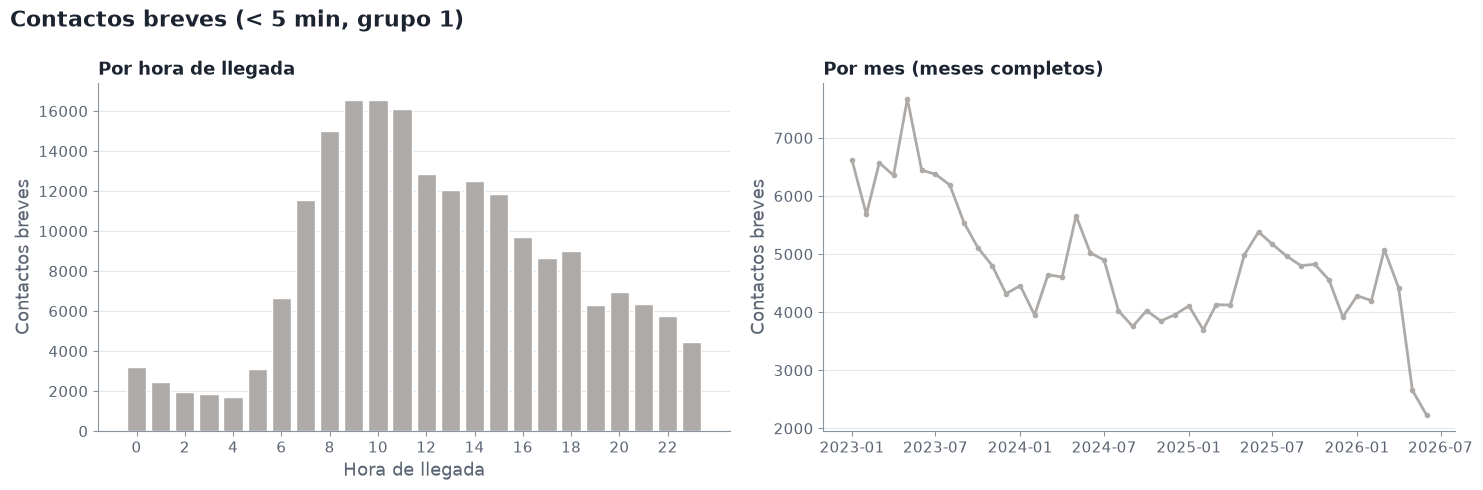

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
n_hora = enmascarar_pequenos(por_hora['n_contactos_breves'], por_hora['n_contactos_breves'])
ejes[0].bar(n_hora.index, n_hora, color=COLORES_GRUPO[G1], edgecolor='white', linewidth=1)
ejes[0].set_xticks(range(0, 24, 2))
ejes[0].set_xlabel('Hora de llegada')
ejes[0].set_ylabel('Contactos breves')
ejes[0].set_title('Por hora de llegada', fontsize=13)

n_mes = enmascarar_pequenos(por_mes['n_contactos_breves'], por_mes['n_contactos_breves'])
ejes[1].plot(n_mes.index, n_mes, marker='o', markersize=3, color=COLORES_GRUPO[G1])
ejes[1].set_ylabel('Contactos breves')
ejes[1].set_title('Por mes (meses completos)', fontsize=13)

fig.suptitle('Contactos breves (< 5 min, grupo 1)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar_figura(fig, '03_contactos_breves')
plt.show()

## 8. Resumen para el dashboard

Tabla larga con el resumen del LOS de los grupos 2 y 3 por dimensión (total, grupo etario, sexo, hora, día de la semana y mes hasta el corte). Agregada y con supresión de celdas pequeñas; se exporta a `data/processed/resumen_los.csv`.

In [22]:
dimensiones = ['total', 'grupo_etario', 'sexo', 'hora_llegada', 'dia_semana', 'mes']
partes = []
for dimension in dimensiones:
    datos = tiempos
    if dimension == 'mes':
        datos = datos[datos['llegada'] <= config.FECHA_CORTE_TENDENCIAS]
        categoria = datos['mes'].dt.strftime('%Y-%m')
    elif dimension == 'total':
        categoria = pd.Series('total', index=datos.index)
    elif dimension == 'dia_semana':
        categoria = datos['dia_semana'].map(dict(enumerate(DIAS_SEMANA)))
    else:
        categoria = datos[dimension].astype(str)
    tabla = tabla_los(datos.assign(categoria=categoria), ['grupo', 'categoria'])
    partes.append(tabla.assign(dimension=dimension).set_index('dimension', append=True))

resumen_los = pd.concat(partes).reorder_levels(['dimension', 'grupo', 'categoria'])
resumen_los_seguro = tabla_segura(resumen_los, decimales=3)

config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
resumen_los_seguro.reset_index().to_csv(config.DATA_PROCESSED / 'resumen_los.csv', index=False)
print('Filas exportadas a data/processed/resumen_los.csv:', len(resumen_los_seguro))

Filas exportadas a data/processed/resumen_los.csv: 160
